# Parte Específica: Visualização explanatória 2

**Pergunta que a visualização responde:** quem tem mais produtos do banco cancela menos o cartão?

**Variável:** `Total_Relationship_Count` (quantidade de produtos do banco que o cliente tem), comparada com a
taxa de cancelamento (`Attrition_Flag`).

**Tipo de gráfico:** barras da taxa de cancelamento por número de produtos, com a conclusão no título.

In [1]:
# [IA] Claude Code – importação das bibliotecas, leitura do dataset tratado, rótulos e cores do grupo
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from taxas import taxa_do_recorte, taxa_por_categoria

CAMINHO_DADOS = Path("../../out/parte_especifica/bankchurners_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# As mesmas cores do grupo em todos os gráficos: azul = ficou, vermelho = cancelou
ROTULOS_SITUACAO = {"Existing Customer": "Ficou", "Attrited Customer": "Cancelou"}
ORDEM_SITUACAO = ["Ficou", "Cancelou"]
CORES_SITUACAO = {"Ficou": "#4C72B0", "Cancelou": "#C44E52"}
ALVO, CANCELOU = "Attrition_Flag", "Attrited Customer"

df = pd.read_csv(CAMINHO_DADOS)
df["Situacao"] = df[ALVO].map(ROTULOS_SITUACAO)
assert df["Situacao"].notna().all()
taxa_base = (df[ALVO] == CANCELOU).mean() * 100
print(f"{len(df)} clientes | taxa de cancelamento da base: {taxa_base:.1f}%")

10127 clientes | taxa de cancelamento da base: 16.1%


In [2]:
# [IA] Claude Code – números que acompanham o gráfico: taxa de cancelamento por número de produtos e comparação entre os grupos
por_produtos = taxa_por_categoria(df, "Total_Relationship_Count", ALVO, CANCELOU)
display(por_produtos.round(1).rename(columns={"n": "clientes", "positivos": "cancelaram", "taxa": "taxa (%)"}))

poucos = df["Total_Relationship_Count"] <= 2
muitos = df["Total_Relationship_Count"] >= 4
cancelou = df[ALVO] == CANCELOU
taxa_poucos = taxa_do_recorte(df, poucos, ALVO, CANCELOU)
taxa_muitos = taxa_do_recorte(df, muitos, ALVO, CANCELOU)
razao = taxa_poucos / taxa_muitos
print(f"1 ou 2 produtos: {taxa_poucos:.1f}% cancelam | 4 a 6 produtos: {taxa_muitos:.1f}% | diferença: {razao:.1f}x")
print(f"3 produtos (intermediário, fora da comparação): {por_produtos.loc[3, 'taxa']:.1f}% cancelam")
print(f"Clientes com 1 ou 2 produtos: {poucos.mean() * 100:.1f}% da base e {poucos[cancelou].mean() * 100:.1f}% de quem cancelou")

,clientes,cancelaram,taxa (%)
Total_Relationship_Count,,,
1,910,233,25.6
2,1243,346,27.8
3,2305,400,17.4
4,1912,225,11.8
5,1891,227,12.0
6,1866,196,10.5


1 ou 2 produtos: 26.9% cancelam | 4 a 6 produtos: 11.4% | diferença: 2.4x
3 produtos (intermediário, fora da comparação): 17.4% cancelam
Clientes com 1 ou 2 produtos: 21.3% da base e 35.6% de quem cancelou


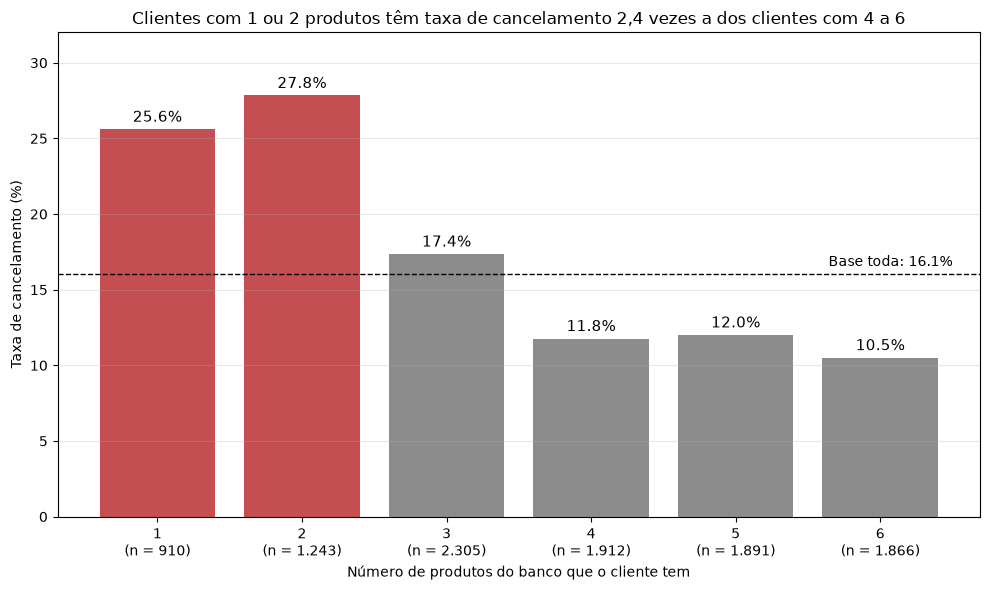

In [3]:
# [IA] Claude Code – gráfico de barras da taxa de cancelamento por número de produtos, com destaque e linha da taxa da base
fig, ax = plt.subplots(figsize=(10, 6))
cores = [CORES_SITUACAO["Cancelou"] if p <= 2 else "#8C8C8C" for p in por_produtos.index]
barras = ax.bar(range(len(por_produtos)), por_produtos["taxa"], color=cores)
for barra, taxa in zip(barras, por_produtos["taxa"]):
    ax.text(barra.get_x() + barra.get_width() / 2, taxa + 0.5, f"{taxa:.1f}%", ha="center", fontsize=11)
ax.axhline(taxa_base, color="black", linestyle="--", linewidth=1)
ax.text(len(por_produtos) - 0.5, taxa_base + 0.5, f"Base toda: {taxa_base:.1f}%", ha="right", fontsize=10)
ax.set_xticks(range(len(por_produtos)))
ax.set_xticklabels([f"{p}\n(n = {n:,})".replace(",", ".") for p, n in zip(por_produtos.index, por_produtos["n"])])
ax.set_xlabel("Número de produtos do banco que o cliente tem")
ax.set_ylabel("Taxa de cancelamento (%)")
ax.set_title(f"Clientes com 1 ou 2 produtos têm taxa de cancelamento {razao:.1f} vezes a dos clientes com 4 a 6".replace(".", ","))
ax.set_ylim(0, por_produtos["taxa"].max() * 1.15)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "viz_explanatoria_2_barras_produtos.png", dpi=150, bbox_inches="tight")
plt.show()

## Nota analítica

**O que está sendo mostrado:** O gráfico mostra a taxa de cancelamento dos clientes de acordo com a quantidade de produtos que possuem no banco, de 1 a 6. Também apresenta a quantidade de clientes em cada grupo e uma linha de referência com a taxa geral de cancelamento da base, que é de 16,1%.

**Qual insight pode ser extraído:** Clientes que possuem apenas 1 ou 2 produtos apresentam uma taxa de cancelamento maior, de 26,9%. Já entre os clientes que possuem de 4 a 6 produtos, a taxa cai para 11,4%. Ou seja, clientes com menos produtos cancelam aproximadamente 2,4 vezes mais. Outro ponto importante é que os clientes com 1 ou 2 produtos representam apenas 21,3% da base, mas correspondem a 35,6% de todos os cancelamentos. Isso mostra que ter poucos produtos contratados pode ser um sinal de maior risco de cancelamento.

**Por que este tipo de visualização:** O gráfico de barras foi escolhido porque facilita comparar valores entre categorias diferentes, nesse caso, a quantidade de produtos contratados. Assim, fica fácil perceber quais grupos possuem as maiores e menores taxas de cancelamento. O vermelho foi usado para destacar os clientes com 1 ou 2 produtos, pois são os grupos que apresentam maior taxa de cancelamento e merecem mais atenção. A linha tracejada permite comparar cada grupo com a taxa geral da base.
